In [1]:
import math
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
train = (
    pd.read_csv('../Datasets/train.csv')
    .rename(columns={'market_forward_excess_returns': 'target'})
)

# Cast all columns except 'date_id' to float
cols_to_cast = [c for c in train.columns if c != 'date_id']
train[cols_to_cast] = train[cols_to_cast].astype(float)

train

,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,target
0,0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9016,9016,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.208995,0.484788,0.717308,0.677249,-0.327455,0.083995,-0.380452,-0.000015,0.000151,-0.000477
9017,9017,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.082011,0.482804,1.001028,0.596561,-0.372979,0.094246,-0.427355,-0.005199,0.000150,-0.005661
9018,9018,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.334656,0.486772,0.894502,0.656746,-0.282024,0.090608,-0.381337,0.005930,0.000150,0.005467
9019,9019,0.0,0.0,0.0,1.0,0.0,-1.0,0.0,0.0,0.0,...,0.163360,0.492725,1.117639,0.674603,-0.445261,0.106481,-0.477635,0.008173,0.000150,0.007710


In [21]:
def plot_moving_average(
    feature,
    window=1260,
    center=True,
    min_periods=630,
    figsize=(10, 5)
):

    moving_average = feature.rolling(
        window=window,
        center=center,
        min_periods=min_periods
    ).mean()

    ax = feature.plot(style='.', color='0.5', figsize=figsize)
    moving_average.plot(
        ax=ax, linewidth=3, title='1260-day moving average of {}'.format(feature.name), legend=False
    )
    plt.show()

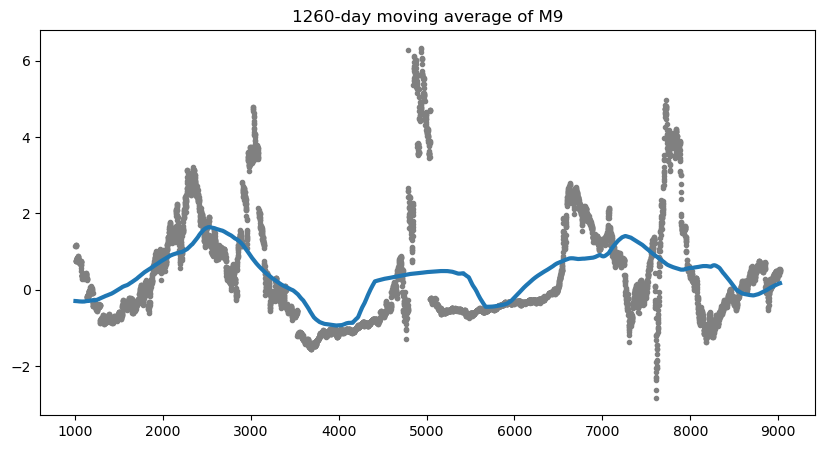

In [22]:
plot_moving_average(train['M9'])

## Periodogram

In [9]:
from scipy.signal import periodogram

def compute_periodogram(ts, detrend='constant'):
    fs = 252
    ts = ts.dropna()
    freq, power = periodogram(ts, fs=fs, detrend=detrend, window='hann', scaling='spectrum')
    return freq, power

In [10]:
freq, power = compute_periodogram(train['M9'])

In [11]:
pd.Series(power, index=freq).sort_values(ascending=False).head(10)

0.125764    0.728719
0.157205    0.362825
0.282969    0.350974
0.094323    0.346734
0.251528    0.294404
0.031441    0.152675
0.408734    0.138632
0.440175    0.098684
0.534498    0.097992
0.377293    0.091512
dtype: float64

In [12]:
bands = {
    'Annual': (0, 1.5),
    'Semi-Annual': (1.5, 3),
    'Quarterly': (3, 8),
    'Monthly': (8, 15),
    'Bi-weekly': (15, 35),
    'Weekly': (35, 60),
    'High-Frequence Noise': (60, 126)
}

band_power = {
    name: power[(freq >= low) & (freq < high)].sum()
    for name, (low, high) in bands.items()
}
band_power_share = pd.Series(band_power) / power.sum() * 100
band_power_share.sort_values(ascending=False)

Annual                  93.245959
Quarterly                3.094568
Semi-Annual              1.915015
Monthly                  0.740778
Bi-weekly                0.523799
High-Frequence Noise     0.304974
Weekly                   0.174908
dtype: float64

## Seasonality

In [25]:
X = train.copy()

X['week_id'] = X['date_id'] // 5  # week index
X['day_in_week'] = X['date_id'] % 5  # 0-4, position inside week
X['week_in_year'] = X['week_id'] % 51  # week position within each trading year (resets every 51 weeks)

X['bi_weekly_id'] = X['date_id'] // 10  # bi-week index
X['day_in_bi_week'] = X['date_id'] % 10  # 0-9, position inside bi-week
X['bi_week_in_year'] = X['bi_weekly_id'] % 26  # week position within each trading year (resets every 26 weeks)

X['month_id'] = X['date_id'] // 21  # month index
X['day_in_month'] = X['date_id'] % 21  # 0-20, position inside month
X['month_in_year'] = X['month_id'] % 12  # month position within each trading year (resets every 12 months)

X['quarter_id'] = X['date_id'] // 63
X['day_in_quarter'] = X['date_id'] % 63
X['quarter_in_year'] = X['quarter_id'] % 4

X['halfyear_id'] = X['date_id'] // 126
X['day_in_halfyear'] = X['date_id'] % 126
X['half_in_year'] = X['halfyear_id'] % 2

X['year_id'] = X['date_id'] // 252
X['day_in_year'] = X['date_id'] % 252
X['year_in_cycle'] = X['year_id'] % X['year_id'].nunique()

In [26]:
def plot_seasonality(X, target='target', period=None, subperiod=None):
    """
    Captures both intra- and inter-seasonal effects
    """

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(2, 2, figsize=(18, 10))

    # Intra-period line plot
    sns.lineplot(
        x=period,
        y=target,
        data=X.groupby(period, as_index=False)[target].mean(),
        ax=axes[0, 0],
        marker='o',
    )
    axes[0, 0].set_title(f"Intra-{period.replace('_', ' ').title()} Seasonality", fontsize=12)
    axes[0, 0].set_xlabel(period.replace('_', ' ').title())
    axes[0, 0].set_ylabel(f"Mean {target.title()}")

    # Heatmap of intra-period stability per year
    pivot1 = X.pivot_table(values=target, index='year_id', columns=period, aggfunc='mean')
    sns.heatmap(pivot1, cmap='coolwarm', center=0, ax=axes[0, 1])
    axes[0, 1].set_title(f"{period.replace('_', ' ').title()} Pattern", fontsize=12)
    axes[0, 1].set_xlabel(period.replace('_', ' ').title())
    axes[0, 1].set_ylabel('year_id'.replace('_', ' ').title())

    # Inter-period line plot
    sns.lineplot(
        x=subperiod,
        y=target,
        data=X.groupby(subperiod, as_index=False)[target].mean(),
        ax=axes[1, 0],
        marker='o',
    )
    axes[1, 0].set_title(f"Inter-{subperiod.replace('_', ' ').title()} Seasonality", fontsize=12)
    axes[1, 0].set_xlabel(subperiod.replace('_', ' ').title())
    axes[1, 0].set_ylabel(f"Mean {target.title()}")

    # Heatmap of inter-period stability per year
    pivot2 = X.pivot_table(values=target, index='year_id', columns=subperiod, aggfunc='mean')
    sns.heatmap(pivot2, cmap='coolwarm', center=0, ax=axes[1, 1])
    axes[1, 1].set_title(f"{subperiod.replace('_', ' ').title()} Pattern", fontsize=12)
    axes[1, 1].set_xlabel(subperiod.replace('_', ' ').title())
    axes[1, 1].set_ylabel('year_id'.replace('_', ' ').title())

    plt.tight_layout()
    plt.show()

### Quarterly

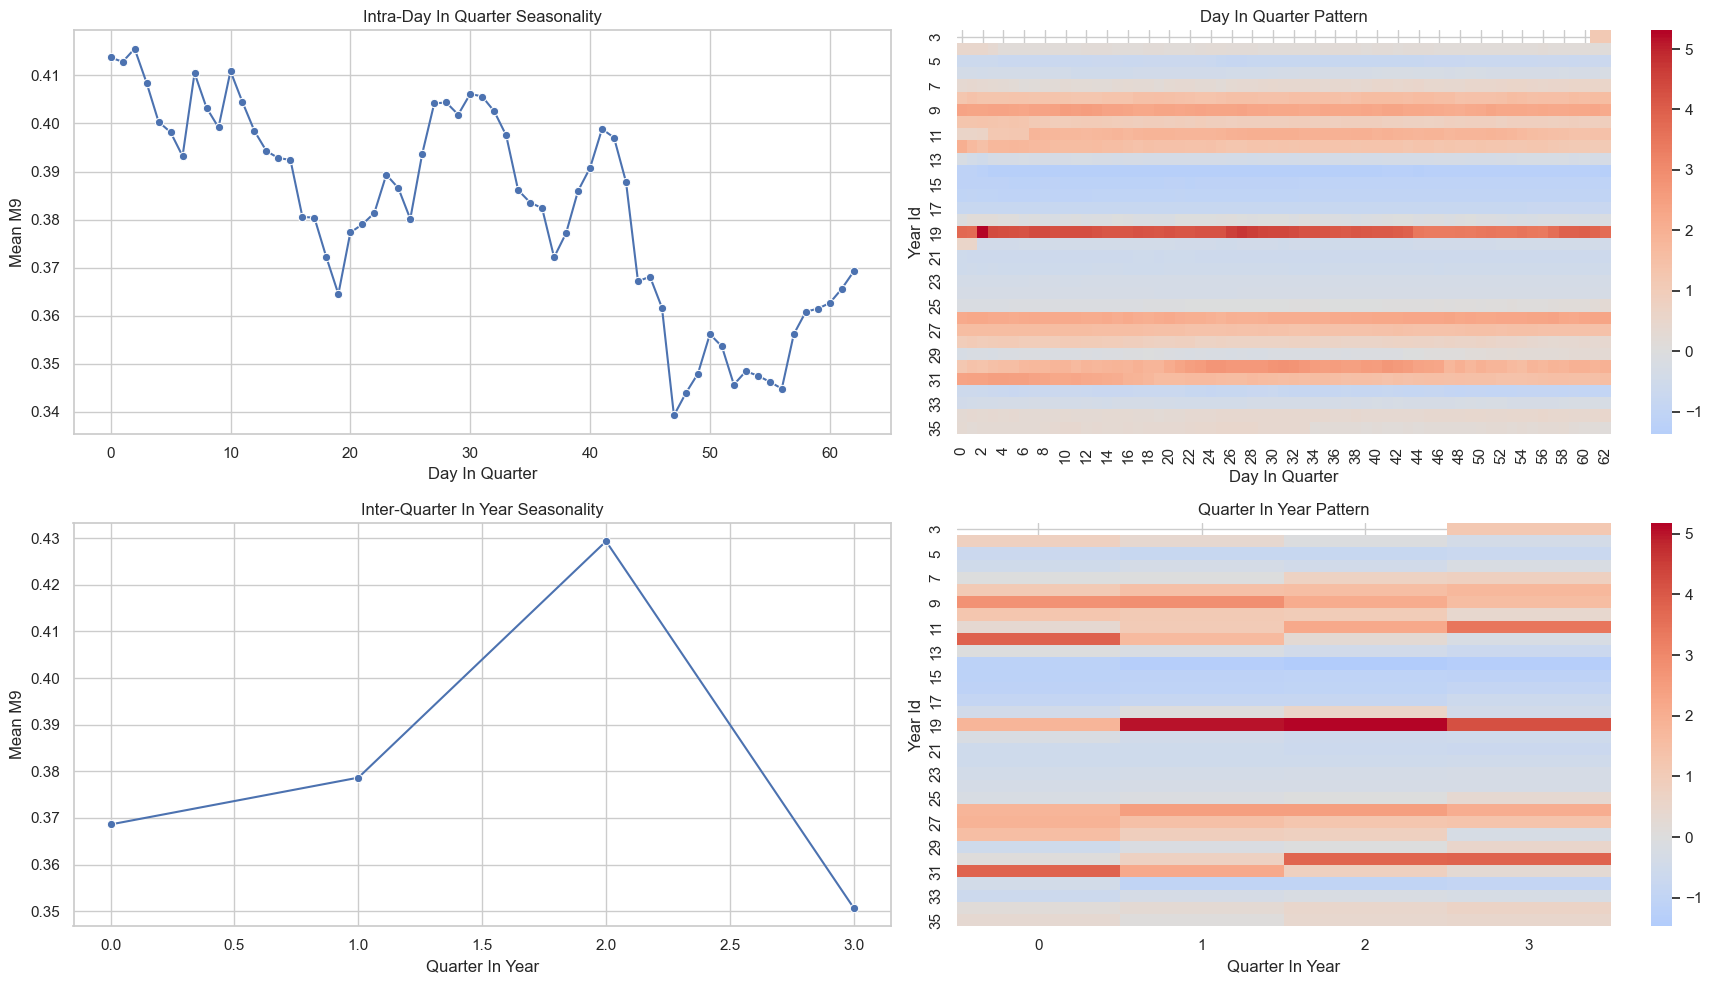

In [28]:
plot_seasonality(
    X,
    target='M9',
    period='day_in_quarter',
    subperiod='quarter_in_year'
)

### Annual

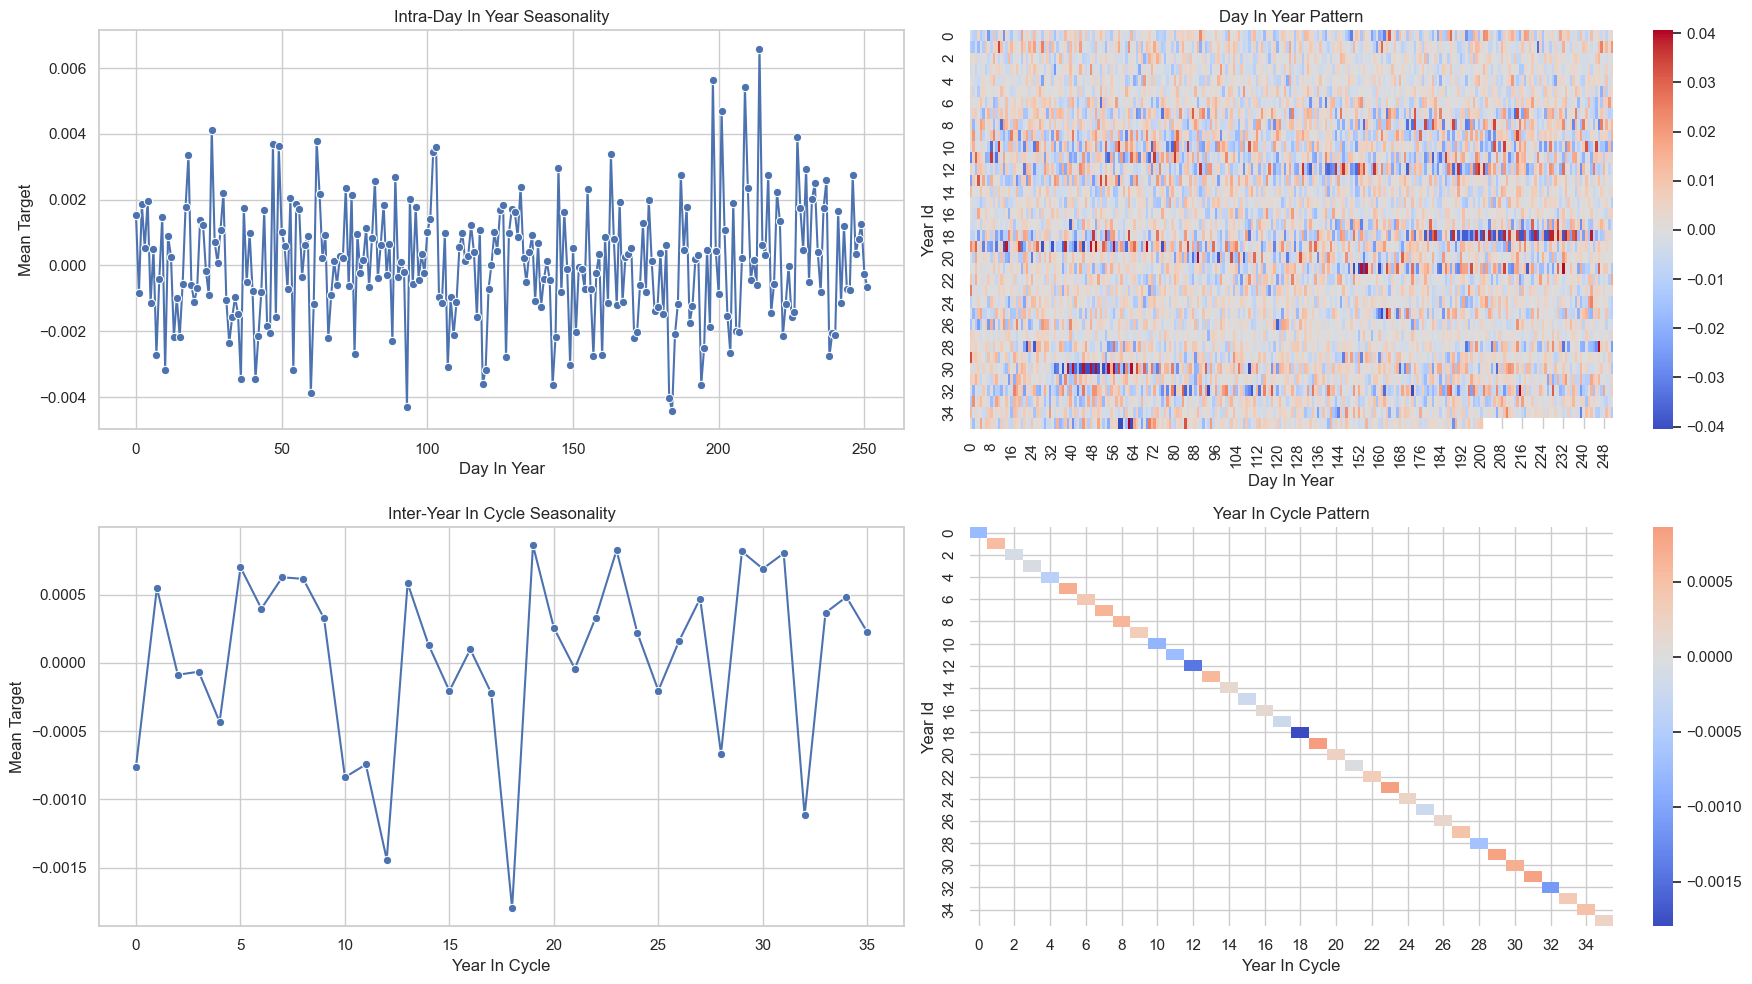

In [29]:
plot_seasonality(
    X,
    period='day_in_year',
    subperiod='year_in_cycle'
)